<table style="width:100%; font-size:11pt; border-collapse:collapse">
    <tr>
        <td colspan="2"
            style="border: 1px #44a305 solid;
                   background-color:#F4F9E6;
                   color:#6ba340;
                   text-align:center;
                   font-weight:bold;
                   padding:8px;">
            Universidad de Oriente
        </td>
    </tr>
    <tr>
        <td style="border: 1px #44a305 solid;
                   background-color:#F4F9E6;
                   color:#6ba340;
                   width:50%;
                   text-align:center;
                   padding:6px;">
                            Métodos Numéricos
        </td>
        <td style="border: 1px #44a305 solid;
                   background-color:#F4F9E6;
                   color:#6ba340;
                   width:50%;
                   text-align:center;
                   padding:6px;">
            Clase 20 - Método de Traub
        </td>
    </tr>
    <tr>
 

</table>

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Método de Traub

In [2]:
def Traub(f, df, x0, tol, maxiter):
    iters = 0
    error = tol+1

    while iters<=maxiter and error>tol:
        y = x0 - f(x0)/df(x0)
        x = y-f(y)/df(x0)
        error = math.fabs(x-x0)
        iters = iters + 1
        x0 = x

    return [x, iters, error]


# Método de Traub con ACOC

In [3]:
def TraubACOC(f,df,x0,tol,maxiter):
    iters = 0
    error = tol+1
    error_x = list()

    while error>tol and iters<=maxiter:

        y = x0-f(x0)/df(x0)
        x = y-f(y)/df(x0)
        error = math.fabs(x-x0)
        error_x.append(error)
        iters = iters+1
        x0 = x

    error_x = np.array(error_x)
    ACOC = np.log(error_x[2:]/error_x[1:-1])/np.log(error_x[1:-1]/error_x[0:-2])

    return [x,iters,error,ACOC]

# Tabla método de Traub

In [4]:
def Traubtabla(f,df,x0,tol,maxiter):
    iters = 0
    error = tol+1
    lista_x = list(); lista_e = list() #Se crean listas para x y el error

    while error>tol and iters<=maxiter:
        y = x0-f(x0)/df(x0)
        x = y-f(y)/df(x0)
        error = math.fabs(x-x0)
        iters = iters+1
        x0 = x
        lista_x.append(x); lista_e.append(error);
    tabla = pd.DataFrame({'Iteraciones': lista_x, 'Error': lista_e}) #Se crear el dataframe
    pd.set_option('display.precision', 12)
    return tabla

# Ejemplo 1

Resolver $x^5-3x+1=0$ con una tolerancia de $10^{-10}$ y una estimación de $x_0=1$

In [5]:
#Definimos f
f = lambda x: x**5 - 3*x+1

#Definimos la derivada de f
df = lambda x: 5*x**4 - 3

tol = 1e-10
x0 = 1
maxiter = 30

x, iters, error = Traub(f,df, x0, tol, maxiter)

In [6]:
print("La solucion a la ecuacion es x =%s" % x)
print("El numero de iteraciones fueron %s" % iters)
print("El error fue de %s" %error)

La solucion a la ecuacion es x =0.3347341419433527
El numero de iteraciones fueron 5
El error fue de 5.551115123125783e-17


In [7]:
Traubtabla(f,df,x0,tol,maxiter)

,Iteraciones,Error
0,-0.546875000000,1.546875000000e+00
1,0.318505242078,8.653802420779e-01
2,0.334734025500,1.622878342214e-02
3,0.334734141943,1.164433022782e-07
4,0.334734141943,5.551115123126e-17


# Ejemplo 2

Resolver la ecuación $e^{-x^2}-\cos(x)=0$, usando una tolerancia de $10^{-6}$ y una estimación de $x_0=2$. Obtener el ACOC

$f(x)=e^{-x^2}-\cos(x)  \quad \quad f'(x)=-2xe^{-x^2}+\sin(x)$

In [8]:
#Definimos f

f= lambda x: math.exp(-x**2)-math.cos(x)

#Introducir la derivada de f
df = lambda x: -2*x*math.exp(-x**2)+math.sin(x)

x0=2
tol=1e-6
maxiter=30

x,iters,error,ACOC = TraubACOC(f,df,x0,tol,maxiter)

In [9]:
ACOC

array([2.28606906])

In [10]:
print("La solucion a la ecuacion es x =%s" % x)
print("El numero de iteraciones fueron %s" % iters)
print("El error fue de %s" %error)
print("El vector del ACOC es de %s" %ACOC)

La solucion a la ecuacion es x =1.4474142712962368
El numero de iteraciones fueron 3
El error fue de 3.799837979823195e-07
El vector del ACOC es de [2.28606906]


In [11]:
Traubtabla(f,df,x0,tol,maxiter)

,Iteraciones,Error
0,1.454709269077,0.545290730923
1,1.447414651280,0.007294617797
2,1.447414271296,0.000000379984


# Ejemplo 3

Resolver $8x-\cos(x)-2x^2=0$.

a) Realizar una representación gráfica de la función para determinar las estimaciones iniciales.

b) Resolver la ecuación con el Método de Traub y una tolerancia de $10^{-8}$

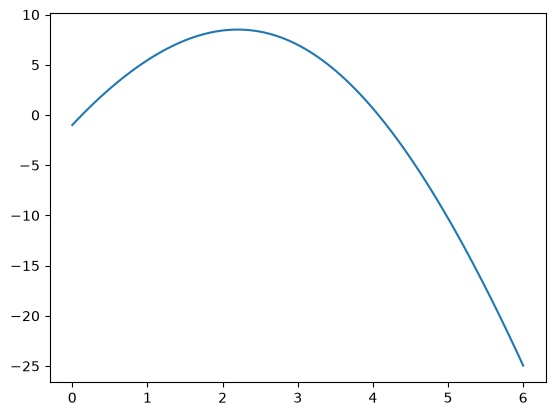

In [12]:
# Representar la funcion en [0,6]
x = np.linspace(0,6,100)
y = 8*x-np.cos(x)-2*x**2
plt.figure()
plt.plot(x,y)
plt.show()

In [13]:
#definimos f
f = lambda x: 8*x-math.cos(x)-2*x**2

#derivada df=8+sin(x)-4x
df = lambda x: 8+math.sin(x)-4*x

tol = 1e-8
x0 = 0
maxiter = 30

x,iters,error = Traub(f,df,x0,tol,maxiter)

In [14]:
print("La solucion a la ecuacion es x = %s" %x)
print("Las iteraciones realizadas fueron %s" %iters)
print("El error que se tuvo fue de %s" %error)

La solucion a la ecuacion es x = 0.12807710275379877
Las iteraciones realizadas fueron 3
El error que se tuvo fue de 2.4347190930029683e-13


In [15]:
Traubtabla(f,df,x0,tol,maxiter)

,Iteraciones,Error
0,0.127930958404,1.279309584037e-01
1,0.128077102754,1.461443498892e-04
2,0.128077102754,2.434719093003e-13


In [16]:
# Encontrar las estimaciones inciales, que  son en x0=0 y x0=4
x0 = 4
x,iters,error = Traub(f,df,x0,tol,maxiter)

In [17]:
print("La solucion a la ecuacion es x = %s" %x)
print("Las iteraciones realizadas fueron %s" %iters)
print("El error que se tuvo fue de %s" %error)

La solucion a la ecuacion es x = 4.073225094959651
Las iteraciones realizadas fueron 3
El error que se tuvo fue de 2.220446049250313e-14


In [18]:
Traubtabla(f,df,x0,tol,maxiter)

,Iteraciones,Error
0,4.073169682819,7.316968281908e-02
1,4.073225094960,5.541214055071e-05
2,4.073225094960,2.220446049250e-14
